In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import scipy.io as sio

BASE = '/content/drive/MyDrive/battery-cycling-quality-analytics'
DATA_RAW = os.path.join(BASE, 'data')
DATA_PROCESSED = os.path.join(BASE, 'data', 'processed')
os.makedirs(DATA_PROCESSED, exist_ok=True)

Mounted at /content/drive


In [4]:
import numpy as np
import pandas as pd
import scipy.io as sio

def parse_cell(mat_path, cell_id):
    """
    Load one NASA PCoE .mat file, walk the nested MATLAB struct,
    and return a long-format pandas DataFrame — one row per measurement sample.
    """
    mat = sio.loadmat(mat_path)
    cycles = mat[cell_id][0, 0]['cycle'][0]

    rows = []
    for cyc_num, cyc in enumerate(cycles, start=1):
        cyc_type = cyc['type'][0]                       # 'charge', 'discharge', or 'impedance'
        amb_temp = float(cyc['ambient_temperature'][0, 0])
        data = cyc['data'][0, 0]
        fields = data.dtype.names

        # Skip impedance cycles — they don't have a time vector
        if 'Time' not in fields:
            continue

        t = data['Time'].flatten()
        n = len(t)

        V = data['Voltage_measured'].flatten() if 'Voltage_measured' in fields else np.full(n, np.nan)
        I = data['Current_measured'].flatten() if 'Current_measured' in fields else np.full(n, np.nan)
        T = data['Temperature_measured'].flatten() if 'Temperature_measured' in fields else np.full(n, np.nan)

        # Capacity is a scalar (only on discharge cycles)
        cap_arr = data['Capacity'].flatten() if 'Capacity' in fields else None
        cap = float(cap_arr[0]) if cap_arr is not None and len(cap_arr) > 0 else np.nan

        for i in range(n):
            rows.append({
                'cell_id': cell_id,
                'cycle_number': cyc_num,
                'cycle_type': cyc_type,
                'ambient_temp_C': amb_temp,
                't_s': t[i],
                'V': V[i],
                'I': I[i],
                'T_cell_C': T[i],
                'capacity_Ah': cap,
            })

    return pd.DataFrame(rows)

In [5]:
import os

BASE = '/content/drive/MyDrive/battery-cycling-quality-analytics'
DATA_RAW = os.path.join(BASE, 'data')
target_file = os.path.join(DATA_RAW, 'B0005.mat')

if not os.path.exists(target_file):
    print(f"Error: File not found at {target_file}")
    print("Please verify that 'B0005.mat' has been uploaded to the 'data' directory in your Google Drive.")
else:
    df = parse_cell(target_file, 'B0005')
    print(df.shape)
    print(df.head())
    print(df['cycle_type'].value_counts())
    print(f"Cycles: {df['cycle_number'].nunique()}")

Error: File not found at /content/drive/MyDrive/battery-cycling-quality-analytics/data/B0005.mat
Please verify that 'B0005.mat' has been uploaded to the 'data' directory in your Google Drive.


In [6]:
import glob

mat_path = glob.glob(os.path.join(DATA_RAW, '**', 'B0005.mat'), recursive=True)[0]
df = parse_cell(mat_path, 'B0005')
print(df.shape)
print(df.head())
print(df['cycle_type'].value_counts())
print(f"Cycles: {df['cycle_number'].nunique()}")

(591458, 9)
  cell_id  cycle_number cycle_type  ambient_temp_C     t_s         V  \
0   B0005             1     charge            24.0   0.000  3.873017   
1   B0005             1     charge            24.0   2.532  3.479394   
2   B0005             1     charge            24.0   5.500  4.000588   
3   B0005             1     charge            24.0   8.344  4.012395   
4   B0005             1     charge            24.0  11.125  4.019708   

          I   T_cell_C  capacity_Ah  
0 -0.001201  24.655358          NaN  
1 -4.030268  24.666480          NaN  
2  1.512731  24.675394          NaN  
3  1.509063  24.693865          NaN  
4  1.511318  24.705069          NaN  
cycle_type
charge       541173
discharge     50285
Name: count, dtype: int64
Cycles: 338


In [7]:
import glob

cell_ids = ['B0005', 'B0006', 'B0007', 'B0018']
all_dfs = []

for cid in cell_ids:
    matches = glob.glob(os.path.join(DATA_RAW, '**', f'{cid}.mat'), recursive=True)
    if not matches:
        print(f'  ⚠ {cid}.mat not found, skipping')
        continue
    mat_path = matches[0]
    print(f'Parsing {cid} from {mat_path}...')
    all_dfs.append(parse_cell(mat_path, cid))

full = pd.concat(all_dfs, ignore_index=True)
print()
print(f'Total rows: {len(full):,}')
print(f'Memory in RAM: {full.memory_usage(deep=True).sum() / 1e6:.1f} MB')
print(f'Cells included: {full["cell_id"].unique().tolist()}')

out = os.path.join(DATA_PROCESSED, 'nasa_pcoe_long.parquet')
full.to_parquet(out, compression='snappy')
print(f'Saved → {out}')

Parsing B0005 from /content/drive/MyDrive/battery-cycling-quality-analytics/data/1. BatteryAgingARC-FY08Q4/B0005.mat...
Parsing B0006 from /content/drive/MyDrive/battery-cycling-quality-analytics/data/1. BatteryAgingARC-FY08Q4/B0006.mat...
Parsing B0007 from /content/drive/MyDrive/battery-cycling-quality-analytics/data/1. BatteryAgingARC-FY08Q4/B0007.mat...
Parsing B0018 from /content/drive/MyDrive/battery-cycling-quality-analytics/data/1. BatteryAgingARC-FY08Q4/B0018.mat...

Total rows: 2,089,050
Memory in RAM: 395.4 MB
Cells included: ['B0005', 'B0006', 'B0007', 'B0018']
Saved → /content/drive/MyDrive/battery-cycling-quality-analytics/data/processed/nasa_pcoe_long.parquet


In [8]:
# Check what's actually in the data for B0005
sub = full[full['cell_id'] == 'B0005']
print(f"Total rows for B0005: {len(sub):,}")
print(f"Cycle types present: {sub['cycle_type'].value_counts().to_dict()}")
print(f"First 20 unique cycle numbers: {sorted(sub['cycle_number'].unique())[:20]}")

# Now check the exact filter from Cell 5
one = sub[(sub['cycle_number'] == 2) & (sub['cycle_type'] == 'discharge')]
print(f"\nRows matching (cycle==2, discharge): {len(one)}")

if len(one) > 0:
    print(f"Time range: {one['t_s'].min():.1f} to {one['t_s'].max():.1f} s")
    print(f"Voltage range: {one['V'].min():.2f} to {one['V'].max():.2f} V")
else:
    print("Filter returned nothing — cycle 2 might not be a discharge cycle")
    # Find the first discharge cycle instead
    discharges = sub[sub['cycle_type'] == 'discharge']['cycle_number'].unique()
    print(f"First 10 discharge cycle numbers: {sorted(discharges)[:10]}")

Total rows for B0005: 591,458
Cycle types present: {np.str_('charge'): 541173, np.str_('discharge'): 50285}
First 20 unique cycle numbers: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20)]

Rows matching (cycle==2, discharge): 197
Time range: 0.0 to 3690.2 s
Voltage range: 2.61 to 4.19 V


Plotting 197 rows


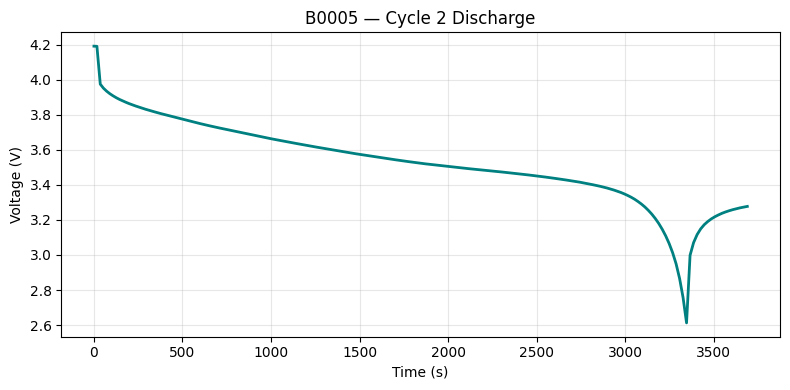

Also saved to /content/test_plot.png — check the file browser


In [10]:
import matplotlib
matplotlib.use('inline')
import matplotlib.pyplot as plt
%matplotlib inline

one = full[(full['cell_id'] == 'B0005')
           & (full['cycle_number'] == 2)
           & (full['cycle_type'] == 'discharge')]

print(f"Plotting {len(one)} rows")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(one['t_s'].values, one['V'].values, color='#008080', linewidth=2)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Voltage (V)')
ax.set_title('B0005 — Cycle 2 Discharge')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
fig.savefig('/content/test_plot.png', dpi=100)
print("Also saved to /content/test_plot.png — check the file browser")